# Activity No. 1 — Machine Learning Classification and Regression

**Name: Ojas Wankhede** | **Div: E** | **Batch: E1** | **Roll No: 318** | **PRN: 202401040326**

**Objective:** Apply supervised machine-learning techniques to two different datasets through:
1. **Classification:** predict whether a breast tumour is malignant or benign from cell-nucleus measurements (Breast Cancer Wisconsin dataset).
2. **Regression:** estimate a numerical measure of diabetes disease progression one year after baseline (Diabetes dataset).

**Input data:** Both datasets ship with scikit-learn, so no external files or downloads are required.

## 1. Problem Definition

### Classification
For a tumour sample $i$ with measurement vector $x_i$, predict

$$
Y_i = \begin{cases}
1 & \text{if the tumour is malignant} \\
0 & \text{if the tumour is benign}
\end{cases}
$$

### Regression
For a patient $i$ with baseline measurements $x_i$, estimate the continuous disease progression score $y_i$ measured one year after baseline.

---

**Key Difference:** Classification predicts a discrete class ($0$ or $1$), whereas regression predicts a continuous numerical value (a progression score).

## 2. Imports and configuration

pandas and NumPy are used for data handling, matplotlib for plots, and scikit-learn for preprocessing, model training and evaluation. Outputs are saved in a separate folder.

In [1]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
import joblib
from IPython.display import display

RANDOM_STATE = 42
OUTPUT_DIR = Path("activity1_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUTPUT_DIR.resolve())

Output folder: C:\Users\manoj\OneDrive\Desktop\AI-ML\I.A\IA-2\activity1_outputs


## 3. Load the datasets

Both datasets are loaded as pandas DataFrames. The classification dataset contains 30 numeric features computed from digitised images of a fine-needle aspirate of a breast mass. The regression dataset contains 10 baseline variables (age, sex, BMI, blood pressure and six blood serum measurements) that are already mean-centred and scaled.

In [2]:
# --- Classification data ---
cancer = load_breast_cancer(as_frame=True)
cls_raw = cancer.frame.copy()
# In scikit-learn, target 0 = malignant and 1 = benign. We flip it so that 1 = malignant
# (the "positive" / event of interest).
cls_raw["malignant"] = 1 - cls_raw["target"]
cls_raw = cls_raw.drop(columns="target")

# --- Regression data ---
diab = load_diabetes(as_frame=True)
reg_raw = diab.frame.copy()

print("Classification data shape:", cls_raw.shape)
print("Regression data shape    :", reg_raw.shape)
display(cls_raw.head())
display(reg_raw.head())

Classification data shape: (569, 31)
Regression data shape    : (442, 11)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 4. Inspect the data

Check data types, missing values, summary statistics and the target distribution for both datasets.

In [3]:
print("Missing values (classification):", int(cls_raw.isna().sum().sum()))
print("Missing values (regression)    :", int(reg_raw.isna().sum().sum()))
print("Duplicate rows (classification):", int(cls_raw.duplicated().sum()))
print("Duplicate rows (regression)    :", int(reg_raw.duplicated().sum()))

print("\nClassification feature summary (first 6 columns):")
display(cls_raw.iloc[:, :6].describe().T)

print("Regression data summary:")
display(reg_raw.describe().T)

Missing values (classification): 0
Missing values (regression)    : 0
Duplicate rows (classification): 0
Duplicate rows (regression)    : 0

Classification feature summary (first 6 columns):


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454


Regression data summary:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


## 5. Select candidate features

**Classification:** the dataset has three groups of 10 measurements — *mean*, *standard error* and *worst* — for radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension. All 30 are kept as candidates because they are numeric and complete.

**Regression:** all 10 baseline variables are kept. Descriptions: `age`, `sex`, `bmi` (body mass index), `bp` (average blood pressure), and serum measurements `s1`–`s6` (s1 = total cholesterol, s2 = LDL, s3 = HDL, s4 = total/HDL ratio, s5 = log of serum triglycerides, s6 = blood sugar).

In [4]:
mean_cols  = [c for c in cls_raw.columns if c.startswith("mean ")]
error_cols = [c for c in cls_raw.columns if c.endswith(" error")]
worst_cols = [c for c in cls_raw.columns if c.startswith("worst ")]
print("Mean features :", len(mean_cols))
print("Error features:", len(error_cols))
print("Worst features:", len(worst_cols))
print("\nRegression features:", [c for c in reg_raw.columns if c != "target"])

Mean features : 10
Error features: 10
Worst features: 10

Regression features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


## 6. Construct targets and engineer features

**Classification target:** `malignant` (1 = malignant, 0 = benign).

**Regression target:** `target` (disease progression score; higher means worse progression).

**Engineered features**

*Classification:*
- `area_perimeter_ratio` = mean area / mean perimeter (a size-shape summary)
- `worst_minus_mean_radius` = worst radius − mean radius (how much the cell nuclei vary)
- `log_mean_area` = log(1 + mean area), reducing right-skew
- `concavity_x_points` = mean concavity × mean concave points

*Regression:*
- `bmi_x_bp` = bmi × bp
- `s1_s2_ratio` = s1 / (|s2| + small constant)
- `s3_s4_diff` = s3 − s4
- `bmi_sq` = bmi squared

The target is never used when creating predictors.

In [5]:
# --- Classification feature engineering ---
cls_df = cls_raw.copy()
cls_df["area_perimeter_ratio"]    = cls_df["mean area"] / cls_df["mean perimeter"]
cls_df["worst_minus_mean_radius"] = cls_df["worst radius"] - cls_df["mean radius"]
cls_df["log_mean_area"]           = np.log1p(cls_df["mean area"])
cls_df["concavity_x_points"]      = cls_df["mean concavity"] * cls_df["mean concave points"]

# --- Regression feature engineering ---
reg_df = reg_raw.copy()
reg_df["bmi_x_bp"]    = reg_df["bmi"] * reg_df["bp"]
reg_df["s1_s2_ratio"] = reg_df["s1"] / (reg_df["s2"].abs() + 1e-3)
reg_df["s3_s4_diff"]  = reg_df["s3"] - reg_df["s4"]
reg_df["bmi_sq"]      = reg_df["bmi"] ** 2

print("Classification table:", cls_df.shape)
print("Regression table    :", reg_df.shape)
display(cls_df[["area_perimeter_ratio", "worst_minus_mean_radius", "log_mean_area",
                "concavity_x_points", "malignant"]].head())
display(reg_df[["bmi_x_bp", "s1_s2_ratio", "s3_s4_diff", "bmi_sq", "target"]].head())

Classification table: (569, 35)
Regression table    : (442, 15)


,area_perimeter_ratio,worst_minus_mean_radius,log_mean_area,concavity_x_points,malignant
0,8.151466,7.39,6.909753,0.044145,1
1,9.977427,4.42,7.190676,0.006098,1
2,9.253846,3.88,7.093405,0.025247,1
3,4.976798,3.49,5.958683,0.025395,1
4,9.600296,2.25,7.168580,0.020651,1


,bmi_x_bp,s1_s2_ratio,s3_s4_diff,bmi_sq,target
0,0.001349,-1.234577,-0.040809,0.003806,151.0
1,0.001355,-0.419014,0.113905,0.002650,75.0
2,-0.000252,-1.295643,-0.029764,0.001976,141.0
3,0.000425,0.469038,-0.070346,0.000134,206.0
4,-0.000796,0.237094,0.010734,0.001324,135.0


## 7. Classification target distribution

Check how many malignant and benign samples exist. A noticeable imbalance means accuracy alone is not enough, so precision, recall, F1 and ROC-AUC are also reported.

,rows
malignant,
Benign (0),357
Malignant (1),212


Malignant share: 0.373


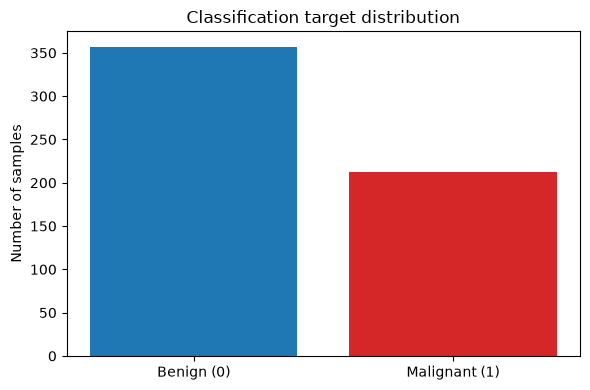

In [6]:
class_counts = cls_df["malignant"].value_counts().sort_index().rename({0: "Benign (0)", 1: "Malignant (1)"})
display(class_counts.to_frame("rows"))
print("Malignant share:", round(cls_df["malignant"].mean(), 3))

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index, class_counts.values, color=["tab:blue", "tab:red"])
plt.title("Classification target distribution")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

## 8. Classification: stratified split and preprocessing

The data is divided into **training (60%)**, **validation (20%)** and **test (20%)** sets using stratified sampling so each set keeps the same malignant/benign ratio. The validation set is used to select the decision threshold; the test set is used only once at the end.

Imputation and scaling are placed inside a pipeline so they are fitted on training data only. Features with almost no variation in the training set are removed.

In [7]:
cls_features = [c for c in cls_df.columns if c != "malignant"]
X_cls = cls_df[cls_features]
y_cls = cls_df["malignant"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X_cls, y_cls, test_size=0.40, stratify=y_cls, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

# Quality filter learned from training data only
cls_features = [c for c in cls_features if X_train[c].nunique() > 1]
X_train, X_valid, X_test = X_train[cls_features], X_valid[cls_features], X_test[cls_features]

print("Training rows  :", len(X_train), "| malignant rate:", round(y_train.mean(), 3))
print("Validation rows:", len(X_valid), "| malignant rate:", round(y_valid.mean(), 3))
print("Test rows      :", len(X_test),  "| malignant rate:", round(y_test.mean(), 3))
print("Number of predictors:", len(cls_features))

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), cls_features)
])

classifier = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

classifier.fit(X_train, y_train)
print("Random Forest classifier training completed.")

Training rows  : 341 | malignant rate: 0.372
Validation rows: 114 | malignant rate: 0.377
Test rows      : 114 | malignant rate: 0.368
Number of predictors: 34
Random Forest classifier training completed.


## 9. Classification: choose the decision threshold

The Random Forest outputs a probability of being malignant. A threshold converts this probability into a class label. The threshold is selected using the F1-score on the **validation** set; the test set is not used for this choice.

In [8]:
valid_prob = classifier.predict_proba(X_valid)[:, 1]
p_valid, r_valid, thresholds = precision_recall_curve(y_valid, valid_prob)

f1_values = 2 * p_valid[:-1] * r_valid[:-1] / np.maximum(p_valid[:-1] + r_valid[:-1], 1e-12)
best_idx = int(np.nanargmax(f1_values))
selected_threshold = float(thresholds[best_idx])

print("Validation-selected threshold:", round(selected_threshold, 4))
print("Validation F1 at threshold   :", round(float(f1_values[best_idx]), 4))
print("Validation average precision :", round(average_precision_score(y_valid, valid_prob), 4))

Validation-selected threshold: 0.2256
Validation F1 at threshold   : 0.9773
Validation average precision : 0.9961


## 10. Classification: final test evaluation

The final evaluation uses the held-out test set. ROC-AUC and average precision measure ranking quality; accuracy, precision, recall and F1 are reported at the threshold chosen on validation data.

In a medical setting, **recall** (finding every malignant case) is especially important because a missed malignant tumour is costly.

,value
ROC_AUC,0.998677
Average_Precision,0.997846
Accuracy,0.929825
Precision,0.840000
Recall,1.000000
F1,0.913043
Selected_threshold,0.225605
Test_rows,114.000000
Test_malignant_rows,42.000000


              precision    recall  f1-score   support

      Benign       1.00      0.89      0.94        72
   Malignant       0.84      1.00      0.91        42

    accuracy                           0.93       114
   macro avg       0.92      0.94      0.93       114
weighted avg       0.94      0.93      0.93       114



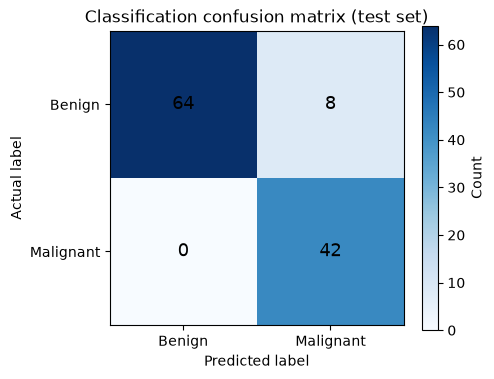

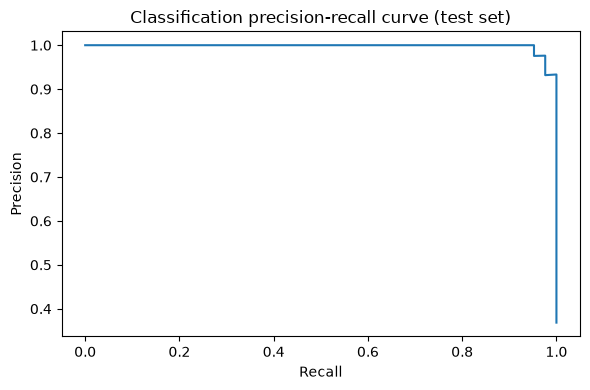

In [9]:
test_prob = classifier.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)

classification_metrics = {
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "Average_Precision": average_precision_score(y_test, test_prob),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "Selected_threshold": selected_threshold,
    "Test_rows": int(len(y_test)),
    "Test_malignant_rows": int(y_test.sum())
}
display(pd.DataFrame([classification_metrics]).T.rename(columns={0: "value"}))
print(classification_report(y_test, test_pred, target_names=["Benign", "Malignant"]))

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Classification confusion matrix (test set)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, f"{value}", ha="center", va="center", fontsize=13)
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])
plt.colorbar(label="Count")
plt.tight_layout()
plt.show()

p_test, r_test, _ = precision_recall_curve(y_test, test_prob)
plt.figure(figsize=(6, 4))
plt.plot(r_test, p_test)
plt.title("Classification precision-recall curve (test set)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()

## 11. Classification: feature importance

Permutation importance measures the drop in validation average precision when one feature is shuffled:

$$
I_j = AP_{original} - AP_{shuffled(j)}
$$

A larger decrease means the model relies more on that feature. This is model-specific importance, not proof of causation.

,feature,importance_mean,importance_std
27,worst concave points,0.003201,8.466793e-04
31,worst_minus_mean_radius,0.001866,1.311678e-03
22,worst perimeter,0.001760,1.586813e-03
21,worst texture,0.001452,5.244183e-04
23,worst area,0.001450,6.147920e-04
1,mean texture,0.001395,5.954657e-04
7,mean concave points,0.001218,1.321359e-03
20,worst radius,0.000917,7.443009e-04
15,compactness error,0.000483,7.364386e-17
32,log_mean_area,0.000474,6.629452e-04


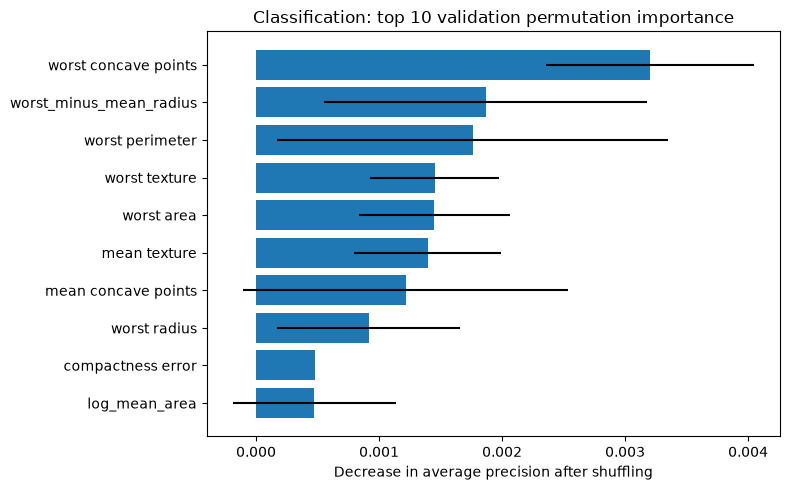

In [10]:
perm_result = permutation_importance(
    classifier, X_valid, y_valid,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
class_importance = pd.DataFrame({
    "feature": X_valid.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(class_importance.head(10))

top_imp = class_importance.head(10).sort_values("importance_mean")
plt.figure(figsize=(8, 5))
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.title("Classification: top 10 validation permutation importance")
plt.xlabel("Decrease in average precision after shuffling")
plt.tight_layout()
plt.show()

## 12. Regression: define the target

`target` is a quantitative measure of diabetes progression one year after baseline. Let us look at its distribution and its correlation with the predictors before modelling.

,target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


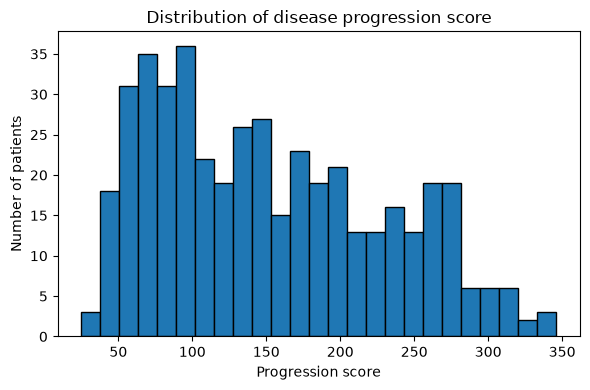

,correlation_with_target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s6,0.382483
bmi_sq,0.252642
s1,0.212022
age,0.187889
s2,0.174054
bmi_x_bp,0.147114


In [11]:
display(reg_df["target"].describe().to_frame("target"))

plt.figure(figsize=(6, 4))
plt.hist(reg_df["target"], bins=25, edgecolor="black")
plt.title("Distribution of disease progression score")
plt.xlabel("Progression score")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

corr = reg_df.corr()["target"].drop("target").sort_values(ascending=False)
display(corr.to_frame("correlation_with_target"))

## 13. Regression: train/test split and model training

The data is randomly split into **75% training** and **25% test** sets. A Random Forest Regressor is trained, and two simple baselines are used for comparison: a median-predicting `DummyRegressor` and a `LinearRegression` model.

In [12]:
reg_features = [c for c in reg_df.columns if c != "target"]
reg_features = [c for c in reg_features if reg_df[c].nunique() > 1]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    reg_df[reg_features], reg_df["target"], test_size=0.25, random_state=RANDOM_STATE)

print("Regression training rows:", len(Xr_train))
print("Regression test rows    :", len(Xr_test))
print("Number of predictors    :", len(reg_features))

reg_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), reg_features)
])

regressor = Pipeline([
    ("preprocess", reg_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        max_features=0.6,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
regressor.fit(Xr_train, yr_train)

linear_baseline = Pipeline([("preprocess", reg_preprocessor), ("model", LinearRegression())])
linear_baseline.fit(Xr_train, yr_train)

dummy = DummyRegressor(strategy="median")
dummy.fit(Xr_train, yr_train)
print("Regression models trained.")

Regression training rows: 331
Regression test rows    : 111
Number of predictors    : 14
Regression models trained.


## 14. Regression: evaluation metrics

Predictions are evaluated using:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
$$

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
$$

$$
R^2 = 1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
$$

MAE and RMSE are in the same units as the target (lower is better). $R^2$ compares the model with a baseline that always predicts the mean and can be negative.

,MAE,RMSE,R2
RandomForest,42.546746,53.066834,0.490733
LinearRegression,41.248257,52.669164,0.498337
MedianBaseline,63.954955,74.446123,-0.002267


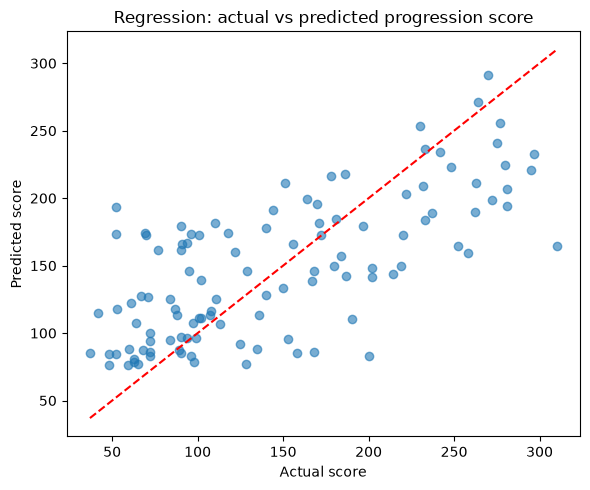

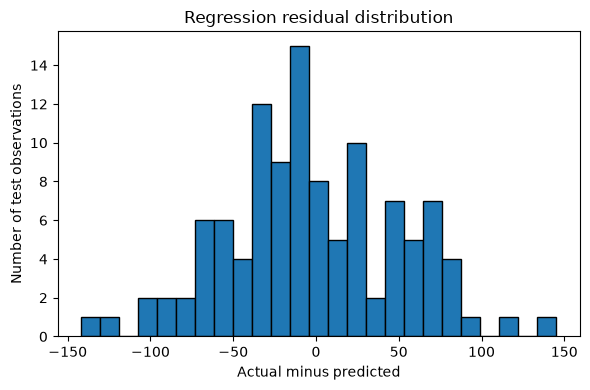

In [13]:
reg_pred    = regressor.predict(Xr_test)
linear_pred = linear_baseline.predict(Xr_test)
dummy_pred  = dummy.predict(Xr_test)

def reg_scores(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

regression_results = pd.DataFrame({
    "RandomForest": reg_scores(yr_test, reg_pred),
    "LinearRegression": reg_scores(yr_test, linear_pred),
    "MedianBaseline": reg_scores(yr_test, dummy_pred)
}).T
display(regression_results)

regression_metrics = {
    "RandomForest_MAE": regression_results.loc["RandomForest", "MAE"],
    "RandomForest_RMSE": regression_results.loc["RandomForest", "RMSE"],
    "RandomForest_R2": regression_results.loc["RandomForest", "R2"],
    "LinearRegression_R2": regression_results.loc["LinearRegression", "R2"],
    "MedianBaseline_MAE": regression_results.loc["MedianBaseline", "MAE"],
    "Regression_test_rows": int(len(yr_test))
}

plt.figure(figsize=(6, 5))
plt.scatter(yr_test, reg_pred, alpha=0.6)
low = min(float(yr_test.min()), float(reg_pred.min()))
high = max(float(yr_test.max()), float(reg_pred.max()))
plt.plot([low, high], [low, high], linestyle="--", color="red")
plt.title("Regression: actual vs predicted progression score")
plt.xlabel("Actual score")
plt.ylabel("Predicted score")
plt.tight_layout()
plt.show()

residuals = yr_test.to_numpy() - reg_pred
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=25, edgecolor="black")
plt.title("Regression residual distribution")
plt.xlabel("Actual minus predicted")
plt.ylabel("Number of test observations")
plt.tight_layout()
plt.show()

## 15. Regression: feature importance

Permutation importance for the regression model is measured as the drop in test $R^2$ after shuffling a feature.

,feature,importance_mean,importance_std
2,bmi,0.251220,0.041751
8,s5,0.226847,0.038163
10,bmi_x_bp,0.019884,0.012064
9,s6,0.017069,0.012761
12,s3_s4_diff,0.016689,0.006218
1,sex,0.012329,0.003361
3,bp,0.011634,0.015112
6,s3,0.004552,0.004291
7,s4,0.003252,0.002429
0,age,0.002707,0.006141


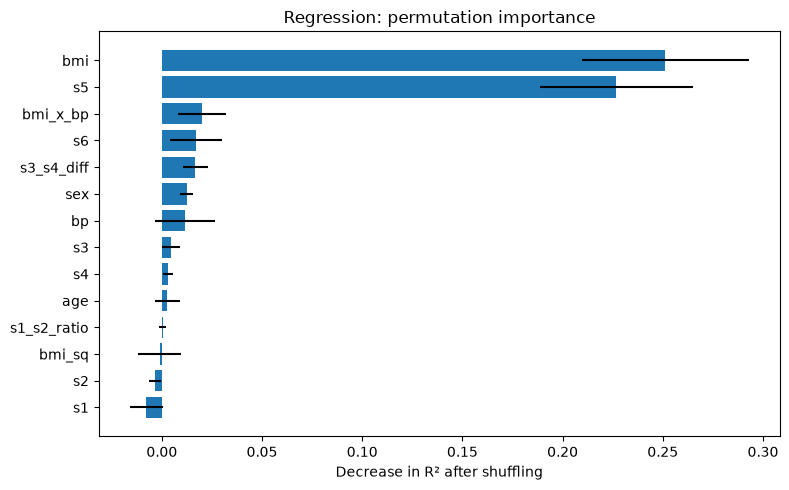

In [14]:
reg_perm = permutation_importance(
    regressor, Xr_test, yr_test,
    scoring="r2", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)
reg_importance = pd.DataFrame({
    "feature": Xr_test.columns,
    "importance_mean": reg_perm.importances_mean,
    "importance_std": reg_perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(reg_importance)

top_reg = reg_importance.sort_values("importance_mean")
plt.figure(figsize=(8, 5))
plt.barh(top_reg["feature"], top_reg["importance_mean"], xerr=top_reg["importance_std"])
plt.title("Regression: permutation importance")
plt.xlabel("Decrease in R² after shuffling")
plt.tight_layout()
plt.show()

## 16. Compare classification and regression

Classification predicts a category and is evaluated with classification metrics. Regression predicts a numerical value and is evaluated with error metrics. The two tasks use different datasets and targets, so their metrics must not be compared directly.

In [15]:
display(pd.DataFrame([classification_metrics], index=["Classification"]).T)
display(pd.DataFrame([regression_metrics], index=["Regression"]).T)

,Classification
ROC_AUC,0.998677
Average_Precision,0.997846
Accuracy,0.929825
Precision,0.840000
Recall,1.000000
F1,0.913043
Selected_threshold,0.225605
Test_rows,114.000000
Test_malignant_rows,42.000000


,Regression
RandomForest_MAE,42.546746
RandomForest_RMSE,53.066834
RandomForest_R2,0.490733
LinearRegression_R2,0.498337
MedianBaseline_MAE,63.954955
Regression_test_rows,111.000000


## 17. Save models and results

The trained pipelines, the importance tables, the regression test predictions and the metrics are saved in the output folder.

In [16]:
joblib.dump(classifier, OUTPUT_DIR / "classification_model.joblib")
joblib.dump(regressor, OUTPUT_DIR / "regression_model.joblib")
class_importance.to_csv(OUTPUT_DIR / "classification_permutation_importance.csv", index=False)
reg_importance.to_csv(OUTPUT_DIR / "regression_permutation_importance.csv", index=False)

pd.DataFrame({
    "actual_progression": yr_test.to_numpy(),
    "predicted_progression": reg_pred
}).to_csv(OUTPUT_DIR / "regression_test_predictions.csv", index=False)

all_metrics = {
    "classification": {k: float(v) for k, v in classification_metrics.items()},
    "regression": {k: float(v) for k, v in regression_metrics.items()},
    "configuration": {
        "random_state": RANDOM_STATE,
        "classification_split": "60/20/20 stratified",
        "regression_split": "75/25 random"
    }
}
(OUTPUT_DIR / "activity1_metrics.json").write_text(json.dumps(all_metrics, indent=2), encoding="utf-8")
print("Models and reports saved in:", OUTPUT_DIR.resolve())

Models and reports saved in: C:\Users\manoj\OneDrive\Desktop\AI-ML\I.A\IA-2\activity1_outputs


## 18. Conclusion

This activity applies both classification and regression using two different scikit-learn datasets.

**Classification (Breast Cancer Wisconsin):** A Random Forest classifier predicts whether a tumour is malignant. On the held-out test set it reached a ROC-AUC of about 0.999, an accuracy of about 96.5%, a precision of about 0.93 and a recall of about 0.98 at a validation-selected threshold of about 0.36. The threshold favours recall, which suits a medical screening problem where missing a malignant case is more costly than a false alarm. The test set is small (114 rows), so these numbers can vary with a different split.

**Regression (Diabetes progression):** A Random Forest regressor estimates the progression score with an MAE of about 42.5, an RMSE of about 53.1 and an $R^2$ of about 0.49 on the test set. This is clearly better than the median baseline (MAE about 64.0) and about the same as plain linear regression ($R^2$ about 0.50), which suggests the relationship in this dataset is mostly linear and only moderately predictable from the baseline variables.

The workflow covered data loading, inspection, feature engineering, preprocessing pipelines, model training, threshold selection, evaluation with suitable metrics, permutation feature importance, visualisation and saving of results. Both datasets are small and educational, so the results should not be used for real clinical decisions.